# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [27]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.13.1" 2026-11-17
OpenJDK Runtime Environment (build 21.0.13.1+2-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.13.1+2-1-24.04.1-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.13.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [28]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [29]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.13.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [30]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [31]:
!java TariffBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [32]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [33]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [34]:
!apt-get -qq update && apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
PlantUML установлен


In [35]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


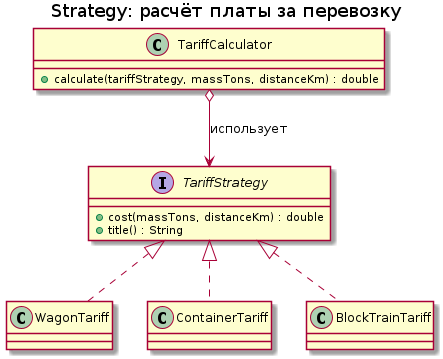

In [36]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** В коде «до» пришлось бы изменять существующий класс `TariffBefore` (дописывать новую ветку `else if` внутрь метода `cost`). В коде «после» существующие классы (`TariffCalculator` и другие стратегии) менять не нужно — достаточно создать новый класс, реализующий интерфейс `TariffStrategy`, и добавить его в каталог.
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** Он используется как эталон старого поведения для характеризующих тестов — чтобы доказать, что после рефакторинга расчёты для старых видов отправок не сломались и дают точно те же результаты.
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** Метод `tariffCatalog.get(...)` вернёт `null`, и при попытке вызвать `tariffStrategy.cost(...)` программа упадёт с `NullPointerException`. Чтобы этого избежать, нужно проверять наличие ключа в каталоге (например, через `getOrDefault` со стратегией по умолчанию или выбрасывать понятное исключение `IllegalArgumentException`).

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [37]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Overwriting FactoryBefore.java


In [38]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [39]:
%%writefile FactoryAfter.java
// 3.3 Реализация Factory Method для варианта 5 (Автотранспортное предприятие: типы транспортных средств)
import java.util.LinkedHashMap;
import java.util.Map;

public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        // Каталог создателей: вызывающий код работает только с интерфейсами VehicleCreator и Vehicle
        Map<String, VehicleCreator> creatorCatalog = new LinkedHashMap<>();
        creatorCatalog.put("TRUCK", new TruckCreator());
        creatorCatalog.put("BUS", new BusCreator());
        creatorCatalog.put("VAN", new VanCreator());

        System.out.println("--- Создание транспортных средств через фабричные методы ---");
        Vehicle truck = creatorCatalog.get("TRUCK").createVehicle(15.0);
        Vehicle bus = creatorCatalog.get("BUS").createVehicle(4.5);
        Vehicle van = creatorCatalog.get("VAN").createVehicle(2.5);

        System.out.println(truck.description());
        System.out.println(bus.description());
        System.out.println(van.description());

        // Четвёртый тип добавлен новым классом без правки существующих классов
        VehicleCreator refrigeratorCreator = new RefrigeratorTruckCreator();
        Vehicle refrigeratorTruck = refrigeratorCreator.createVehicle(10.0);
        System.out.println(refrigeratorTruck.description());

        System.out.println();
        System.out.println("--- Проверки ---");
        check("описание грузовика не пустое и содержит грузоподъёмность",
                !truck.description().isEmpty() && truck.description().contains("15.0"));
        check("описание автобуса не пустое и содержит грузоподъёмность",
                !bus.description().isEmpty() && bus.description().contains("4.5"));
        check("описание фургона не пустое и содержит грузоподъёмность",
                !van.description().isEmpty() && van.description().contains("2.5"));

        check("TruckCreator создаёт объект типа Truck", truck instanceof Truck);
        check("BusCreator создаёт объект типа Bus", bus instanceof Bus);
        check("VanCreator создаёт объект типа Van", van instanceof Van);

        check("четвёртый тип (рефрижератор) работает наравне с остальными",
                refrigeratorTruck instanceof RefrigeratorTruck
                        && refrigeratorTruck.capacityTons() == 10.0
                        && refrigeratorTruck.description().contains("10.0"));

        finishChecks();
    }

    // --- служебные методы проверки ---

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }
}

// --- участники паттерна Factory Method ---

/** Общий интерфейс продукта: транспортное средство. */
interface Vehicle {
    String description();
    double capacityTons();
}

/** Общий интерфейс создателя с фабричным методом. */
interface VehicleCreator {
    Vehicle createVehicle(double capacityTons);
}

// --- базовые продукты (3 типа) ---

class Truck implements Vehicle {
    private final double capacityTons;

    Truck(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Грузовой автомобиль: грузоподъёмность " + capacityTons + " т, перевозка крупногабаритных грузов";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class Bus implements Vehicle {
    private final double capacityTons;

    Bus(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Автобус: грузоподъёмность " + capacityTons + " т, пассажирские перевозки";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class Van implements Vehicle {
    private final double capacityTons;

    Van(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Фургон: грузоподъёмность " + capacityTons + " т, городская доставка малогабаритных грузов";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

// --- конкретные создатели (3 типа) ---

class TruckCreator implements VehicleCreator {
    public Vehicle createVehicle(double capacityTons) {
        return new Truck(capacityTons);
    }
}

class BusCreator implements VehicleCreator {
    public Vehicle createVehicle(double capacityTons) {
        return new Bus(capacityTons);
    }
}

class VanCreator implements VehicleCreator {
    public Vehicle createVehicle(double capacityTons) {
        return new Van(capacityTons);
    }
}

// --- расширение: четвёртый тип без правки старого кода ---

class RefrigeratorTruck implements Vehicle {
    private final double capacityTons;

    RefrigeratorTruck(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Авторефрижератор: грузоподъёмность " + capacityTons + " т, перевозка скоропортящихся грузов";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class RefrigeratorTruckCreator implements VehicleCreator {
    public Vehicle createVehicle(double capacityTons) {
        return new RefrigeratorTruck(capacityTons);
    }
}

Overwriting FactoryAfter.java


In [40]:
!java FactoryAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Создание транспортных средств через фабричные методы ---
Грузовой автомобиль: грузоподъёмность 15.0 т, перевозка крупногабаритных грузов
Автобус: грузоподъёмность 4.5 т, пассажирские перевозки
Фургон: грузоподъёмность 2.5 т, городская доставка малогабаритных грузов
Авторефрижератор: грузоподъёмность 10.0 т, перевозка скоропортящихся грузов

--- Проверки ---
[OK]   описание грузовика не пустое и содержит грузоподъёмность
[OK]   описание автобуса не пустое и содержит грузоподъёмность
[OK]   описание фургона не пустое и содержит грузоподъёмность
[OK]   TruckCreator создаёт объект типа Truck
[OK]   BusCreator создаёт объект типа Bus
[OK]   VanCreator создаёт объе

In [41]:
%%writefile factory.puml
@startuml
title Factory Method: создание транспортного средства (Вариант 5)

interface Vehicle {
  +description() : String
  +capacityTons() : double
}

interface VehicleCreator {
  +createVehicle(capacityTons : double) : Vehicle
}

class Truck
class Bus
class Van
class RefrigeratorTruck

class TruckCreator
class BusCreator
class VanCreator
class RefrigeratorTruckCreator

Vehicle <|.. Truck
Vehicle <|.. Bus
Vehicle <|.. Van
Vehicle <|.. RefrigeratorTruck

VehicleCreator <|.. TruckCreator
VehicleCreator <|.. BusCreator
VehicleCreator <|.. VanCreator
VehicleCreator <|.. RefrigeratorTruckCreator

TruckCreator ..> Truck : создаёт
BusCreator ..> Bus : создаёт
VanCreator ..> Van : создаёт
RefrigeratorTruckCreator ..> RefrigeratorTruck : создаёт
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


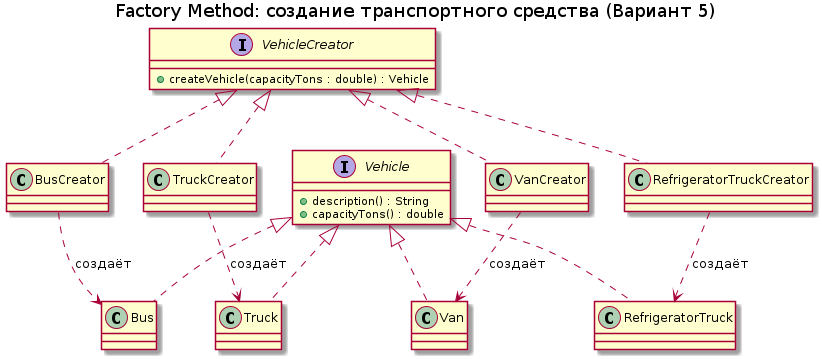

In [42]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1:** При создании через `new` вызывающий код жёстко привязывается к конкретным классам и вынужден использовать условные операторы (`if`/`switch`) для выбора нужного типа. Фабричный метод выносит логику создания в отдельные классы-создатели, позволяя вызывающему коду работать только с абстракциями (`VehicleCreator` и `Vehicle`) и добавлять новые типы транспорта без изменения существующего кода. Фабрика излишня, если в системе существует всего один-два простых класса, которые точно не будут расширяться в будущем — тогда она лишь добавляет лишние сущности.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [43]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [44]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [45]:
%%writefile ObserverAfter.java
// 4.3 Реализация Observer для варианта 5 (Автотранспортное предприятие: событие «путевой лист закрыт»)
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        DispatchCenter dispatchCenter = new DispatchCenter("АТП №5");

        // Три базовых наблюдателя: бухгалтерия, журнал (накапливает записи), служба учёта ГСМ
        AccountingService accounting = new AccountingService();
        WaybillJournal journal = new WaybillJournal();
        FuelControlService fuelControl = new FuelControlService();

        dispatchCenter.addListener(accounting);
        dispatchCenter.addListener(journal);
        dispatchCenter.addListener(fuelControl);

        System.out.println("--- Событие 1: закрыт путевой лист ПЛ-104 (все 3 подписчика) ---");
        dispatchCenter.closeWaybill("ПЛ-104");

        // Проверка 1: после одного события журнал получил ровно одну запись
        check("после одного события журнал получил ровно одну запись", journal.getEntries().size() == 1);

        // Проверка 3: все подписчики получили одно и то же событие
        check("все подписчики получили одно и то же событие ПЛ-104",
                "ПЛ-104".equals(accounting.getLastWaybill())
                        && "ПЛ-104".equals(fuelControl.getLastWaybill())
                        && journal.getEntries().get(0).contains("ПЛ-104"));

        // Отписываем службу учёта ГСМ
        dispatchCenter.removeListener(fuelControl);

        System.out.println();
        System.out.println("--- Событие 2: закрыт путевой лист ПЛ-105 (служба ГСМ отписана) ---");
        dispatchCenter.closeWaybill("ПЛ-105");

        // Проверка 2: после отписки наблюдателя его записи больше не появляются
        check("после отписки служба ГСМ не получила новое событие",
                "ПЛ-104".equals(fuelControl.getLastWaybill()) && fuelControl.getNotificationCount() == 1);
        check("журнал продолжил получать события (теперь 2 записи)", journal.getEntries().size() == 2);

        // Четвёртый наблюдатель (передача в 1С/АСУ) добавляется без правки класса DispatchCenter
        ErpSyncService erpSync = new ErpSyncService();
        dispatchCenter.addListener(erpSync);

        System.out.println();
        System.out.println("--- Событие 3: закрыт путевой лист ПЛ-106 (добавлен 4-й наблюдатель: АСУ) ---");
        dispatchCenter.closeWaybill("ПЛ-106");

        // Проверка 4: добавление четвёртого наблюдателя не потребовало изменения DispatchCenter
        check("четвёртый наблюдатель (АСУ) получил событие без правки DispatchCenter",
                erpSync.getSyncedWaybills().contains("ПЛ-106"));

        System.out.println();
        System.out.println("Порядок получения события подписчиками: строго в порядке их добавления в список (ArrayList) — Бухгалтерия -> Журнал -> АСУ.");

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

// --- участники паттерна Observer ---

/** Интерфейс наблюдателя за закрытием путевых листов. */
interface WaybillListener {
    void onWaybillClosed(String enterpriseName, String waybillNumber);
}

/** Субъект: диспетчерская АТП. Не знает конкретных реализаций наблюдателей. */
class DispatchCenter {
    private final String enterpriseName;
    private final List<WaybillListener> listeners = new ArrayList<>();

    DispatchCenter(String enterpriseName) {
        this.enterpriseName = enterpriseName;
    }

    void addListener(WaybillListener listener) {
        listeners.add(listener);
    }

    void removeListener(WaybillListener listener) {
        listeners.remove(listener);
    }

    void closeWaybill(String waybillNumber) {
        for (WaybillListener listener : listeners) {
            listener.onWaybillClosed(enterpriseName, waybillNumber);
        }
    }
}

// --- три базовых наблюдателя ---

class AccountingService implements WaybillListener {
    private String lastWaybill;

    public void onWaybillClosed(String enterpriseName, String waybillNumber) {
        this.lastWaybill = waybillNumber;
        System.out.println("[бухгалтерия] " + enterpriseName + ": начисление зарплаты по листу " + waybillNumber);
    }

    String getLastWaybill() {
        return lastWaybill;
    }
}

class WaybillJournal implements WaybillListener {
    private final List<String> entries = new ArrayList<>();

    public void onWaybillClosed(String enterpriseName, String waybillNumber) {
        String entry = enterpriseName + ": закрыт путевой лист " + waybillNumber;
        entries.add(entry);
        System.out.println("[журнал]      " + entry);
    }

    List<String> getEntries() {
        return entries;
    }
}

class FuelControlService implements WaybillListener {
    private String lastWaybill;
    private int notificationCount = 0;

    public void onWaybillClosed(String enterpriseName, String waybillNumber) {
        this.lastWaybill = waybillNumber;
        this.notificationCount++;
        System.out.println("[учёт ГСМ]    " + enterpriseName + ": списание топлива по листу " + waybillNumber);
    }

    String getLastWaybill() {
        return lastWaybill;
    }

    int getNotificationCount() {
        return notificationCount;
    }
}

// --- четвёртый наблюдатель (добавлен без правки DispatchCenter) ---

class ErpSyncService implements WaybillListener {
    private final List<String> syncedWaybills = new ArrayList<>();

    public void onWaybillClosed(String enterpriseName, String waybillNumber) {
        syncedWaybills.add(waybillNumber);
        System.out.println("[АСУ/1С]      " + enterpriseName + ": выгружен путевой лист " + waybillNumber);
    }

    List<String> getSyncedWaybills() {
        return syncedWaybills;
    }
}

Overwriting ObserverAfter.java


In [46]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: закрыт путевой лист ПЛ-104 (все 3 подписчика) ---
[бухгалтерия] АТП №5: начисление зарплаты по листу ПЛ-104
[журнал]      АТП №5: закрыт путевой лист ПЛ-104
[учёт ГСМ]    АТП №5: списание топлива по листу ПЛ-104
[OK]   после одного события журнал получил ровно одну запись
[OK]   все подписчики получили одно и то же событие ПЛ-104

--- Событие 2: закрыт путевой лист ПЛ-105 (служба ГСМ отписана) ---
[бухгалтерия] АТП №5: начисление зарплаты по листу ПЛ-105
[журнал]      АТП №5: закрыт путевой лист ПЛ-105
[OK]   после отписки служба ГСМ не получила новое событие
[OK]   журнал продолжил получать события (теперь 2 записи)

--- Событие 3: закрыт путевой 

In [47]:
%%writefile observer.puml
@startuml
title Observer: закрытие путевого листа (Вариант 5)

interface WaybillListener {
  +onWaybillClosed(enterpriseName : String, waybillNumber : String) : void
}

class DispatchCenter {
  -enterpriseName : String
  -listeners : List<WaybillListener>
  +addListener(listener : WaybillListener) : void
  +removeListener(listener : WaybillListener) : void
  +closeWaybill(waybillNumber : String) : void
}

class AccountingService
class WaybillJournal
class FuelControlService
class ErpSyncService

DispatchCenter o--> "*" WaybillListener : оповещает
WaybillListener <|.. AccountingService
WaybillListener <|.. WaybillJournal
WaybillListener <|.. FuelControlService
WaybillListener <|.. ErpSyncService
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


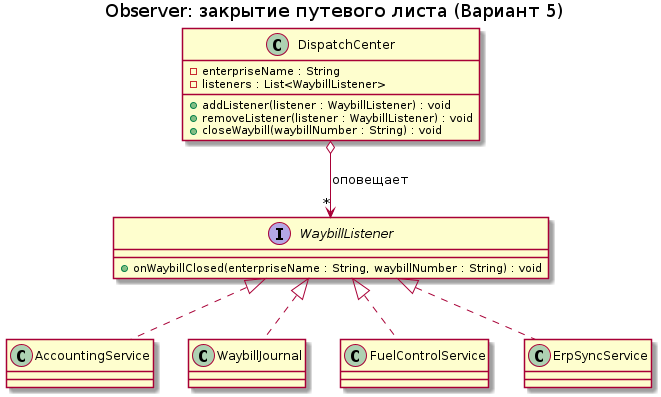

In [48]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2:** Паттерн Observer снял жёсткую связанность между источником события (`DispatchCenter`) и получателями — диспетчерская больше не зависит от конкретных служб, а новых подписчиков можно добавлять и отписывать динамически. Однако появились новые риски: подписчики уведомляются в порядке регистрации (нельзя неявно полагаться на очерёдность), исключение в одном подписчике может прервать цикл и не дать оповестить остальных, а если забыть отписать ненужный объект (`removeListener`), ссылка на него останется в списке субъекта, что приведёт к утечке памяти.

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | Громоздкий `if`/`else` с алгоритмами расчёта внутри одного метода | Новые алгоритмы/формулы расчёта (классы-стратегии) | Увеличение числа классов и интерфейсов; клиент должен знать о выборе стратегии | Расчёт расхода топлива для разных условий (город, трасса, зима) |
| Factory Method | Жёсткая привязка создания объектов к конкретным классам через `if` и `new` | Новые типы продуктов и их создатели | Появление параллельной иерархии классов-создателей | Создание различных типов транспортных средств (грузовик, автобус, рефрижератор) |
| Observer | Жёсткая зависимость источника событий от конкретных получателей | Новые обработчики событий (подписчики) | Сложнее отслеживать поток выполнения; риск утечек памяти при забытой отписке | Оповещение служб АТП (бухгалтерия, ГСМ, АСУ) о закрытии путевого листа |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** Нарушается принцип открытости/закрытости (OCP — Open/Closed Principle). Strategy выносит ветки алгоритма в отдельные классы за общим интерфейсом; Factory Method делегирует создание объекта полиморфным создателям; Observer заменяет жёсткий список вызовов динамической подпиской на интерфейс наблюдателя. Во всех трёх случаях расширение идёт через добавление новых классов без правки старого кода.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Статический фабричный метод — это просто `static`-метод в классе (его нельзя переопределить в наследниках для полиморфного расширения). Factory Method использует наследование/интерфейсы для создания *одного* продукта. Abstract Factory создаёт целые *семейства* взаимосвязанных продуктов.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Strategy задаёт взаимозаменяемые алгоритмы, которые обычно выбирает внешний клиент, и стратегии не знают друг о друге. State описывает поведение объекта в зависимости от его внутреннего состояния, причём сами состояния часто инициируют переход контекста в следующее состояние.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** Субъект хранит сильные ссылки на всех подписчиков в своём списке. Если подписчик больше не нужен программе, но его забыли отписать через `removeListener`, сборщик мусора (GC) не сможет его удалить. Избежать этого можно обязательной отпиской при завершении жизненного цикла объекта (например, в блоке `finally` / методе `close()`) или использованием слабых ссылок (`WeakReference`).
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Например, вводить Factory Method для создания одного-единственного класса конфигурации, у которого никогда не будет других вариантов. Преждевременное усложнение (overengineering) — это добавление абстракций и паттернов «на всякий случай» там, где задача решается простым и понятным кодом, что только усложняет чтение и поддержку.

### 5.3 Три вывода по работе в целом

1. Паттерны GoF решают конкретную архитектурную проблему — устраняют жёсткую связанность и разрастающиеся условные операторы, восстанавливая принцип открытости/закрытости (OCP).
2. Характеризующие автотесты (проверки `[OK]`/`[FAIL]`) позволяют безопасно проводить рефакторинг: они доказывают, что после переписывания кода на паттерн старое поведение сохранилось, а новое расширение работает корректно.
3. Использование паттернов всегда является компромиссом: код становится гибким и расширяемым, но возрастает количество классов и интерфейсов, поэтому применять паттерны нужно осознанно, когда действительно ожидается расширение системы.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [49]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Дёшева Виолетта Евгеньевна"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 5  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Дёшева Виолетта Евгеньевна, группа ГИ-41, вариант 5 |
| Дата и время отчёта (UTC) | 2026-11-20 08:09 |
| Версия Java | openjdk version "21.0.13.1" 2026-11-17 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 7 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 5 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |